<a href="https://colab.research.google.com/github/xXBl4ckXentxX/Deep-Learning/blob/main/Hands_on_4_MLP_From_Scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on 4 — Crear una red neuronal MLP desde cero con NumPy


**Objetivo:** programar una red neuronal capaz de reconocer las especies del conjunto Iris **sin utilizar bibliotecas de redes neuronales para entrenarla**. Las multiplicaciones, las predicciones y la actualización de los pesos serán programadas con **NumPy**.



## 1. ¿Cómo funciona un MLP?

Nuestro modelo recibe 4 mediciones, pasa por una o dos **capas ocultas** y produce 3 probabilidades.

**Ejemplo de arquitectura:** `4 → 8 → 3` (4 entradas, 8 neuronas ocultas, 3 salidas).

Una neurona realiza dos operaciones:

\[
z = x_1w_1 + x_2w_2 + \dots + x_nw_n + b,\qquad a=g(z)
\]

- `x`: los datos de entrada.
- `W`: pesos que la red aprende.
- `b`: sesgos que la red también aprende.
- `g`: función de activación (usaremos ReLU en la red principal).

### Los 4 pasos para aprender

1. **Forward:** calcular la salida que produce la red.
2. **Pérdida:** comparar esa salida con la respuesta correcta mediante **entropía cruzada**.
3. **Backward (retropropagación):** calcular el gradiente, es decir, cómo cambia el error al mover cada peso.
4. **Actualización:** cambiar los pesos y sesgos mediante el **descenso del gradiente**.

\[
W_{nuevo}=W-\eta\,dW, \qquad b_{nuevo}=b-\eta\,db
\]

`η` es la **tasa de aprendizaje**, que controla el tamaño del cambio. Una vuelta completa por todas las muestras se llama **época**. Usaremos *mini-lotes* para actualizar la red con pequeños grupos de flores.

**Modelo matemático de la red:**

\[
Z^{(1)}=XW^{(1)}+b^{(1)},\quad A^{(1)}=ReLU(Z^{(1)})
\]

\[
Z^{(2)}=A^{(1)}W^{(2)}+b^{(2)},\quad \hat Y=softmax(Z^{(2)})
\]

Con una segunda capa oculta se repite el cálculo intermedio. `softmax` asegura que las 3 probabilidades sumen **1**. Para clasificación multiclase, el error se calcula con **entropía cruzada**.

## 2. Preparar el dataset Iris

Iris contiene **150 flores**, con cuatro mediciones en centímetros (largo y ancho de sépalo y pétalo), y tres especies: `setosa`, `versicolor`, `virginica`.

Aquí necesitamos que todo sea un arreglo de NumPy, porque programaremos los cálculos de la red de forma manual.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

SEMILLA = 42                # Permite repetir los experimentos.
iris = load_iris()           # Solo usamos sklearn para cargar el dataset.
columnas = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

# Tabla de apoyo para entender los datos.
df = pd.DataFrame(iris.data, columns=columnas)
df["species"] = iris.target_names[iris.target]

print("Dimensiones:", df.shape)
print(df.head().to_string(index=False))

Dimensiones: (150, 5)
 sepal_length  sepal_width  petal_length  petal_width species
          5.1          3.5           1.4          0.2  setosa
          4.9          3.0           1.4          0.2  setosa
          4.7          3.2           1.3          0.2  setosa
          4.6          3.1           1.5          0.2  setosa
          5.0          3.6           1.4          0.2  setosa


### 2.1 Revisar los datos y convertir las especies a números

Las redes no trabajan con textos como `setosa`, sino con clases **0, 1 y 2**:

| Clase | Especie |
|---|---|
| 0 | setosa |
| 1 | versicolor |
| 2 | virginica |

`X` será una matriz de **150 filas × 4 características** y `y` tendrá **150 etiquetas numéricas**.

In [ ]:
print("Flores por especie:")
print(df["species"].value_counts())
print("Datos faltantes:", df.isnull().sum().sum())
print("\nResumen de las medidas:")
print(df[columnas].describe().round(2))

X = df.iloc[:, 0:4].to_numpy()   # Medidas de las flores.
y = iris.target.copy()            # Especie: 0, 1 o 2.
clases = iris.target_names        # Traducción de cada número a especie.
K = len(clases)                  # Tres especies.

print("\nForma de X:", X.shape, "| Forma de y:", y.shape)

Flores por especie:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64
Datos faltantes: 0

Resumen de las medidas:
       sepal_length  sepal_width  petal_length  petal_width
count        150.00       150.00        150.00       150.00
mean           5.84         3.06          3.76         1.20
std            0.83         0.44          1.77         0.76
min            4.30         2.00          1.00         0.10
25%            5.10         2.80          1.60         0.30
50%            5.80         3.00          4.35         1.30
75%            6.40         3.30          5.10         1.80
max            7.90         4.40          6.90         2.50

Forma de X: (150, 4) | Forma de y: (150,)


### 2.2 Dibujar las flores

Un **scatter plot** (gráfica de puntos) muestra qué tan separadas están las especies. Cada color representa una especie diferente.

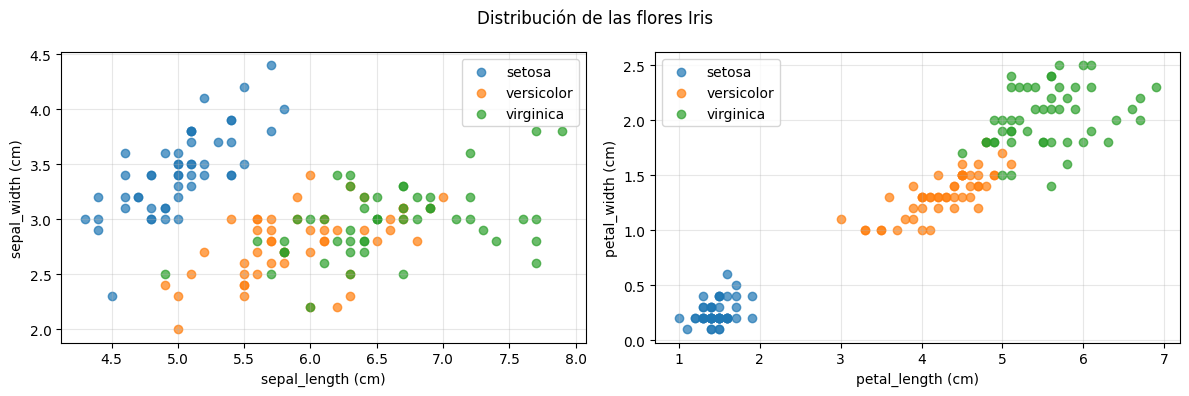

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
pares = [(0, 1), (2, 3)]  # Sépalo (0,1) y pétalo (2,3).

for eje, (x, y_col) in zip(ejes, pares):
    for clase in range(K):
        filas = y == clase
        eje.scatter(X[filas, x], X[filas, y_col], label=clases[clase], alpha=0.7)
    eje.set_xlabel(columnas[x] + " (cm)")
    eje.set_ylabel(columnas[y_col] + " (cm)")
    eje.legend()
    eje.grid(alpha=0.3)

plt.suptitle("Distribución de las flores Iris")
plt.tight_layout()
plt.show()

**Observación:** `setosa` se distingue fácilmente. Las otras dos especies tienen medidas parcialmente similares.

### 2.3 Dividir los datos (80 % entrenamiento y 20 % prueba)

Lo haremos **con NumPy** y manteniendo la misma cantidad proporcional de cada especie. Las 30 muestras de prueba **no se usarán para escoger ni entrenar el modelo**.

In [ ]:
def dividir_estratificado(X, y, proporcion, semilla):
    """Separa una proporción de cada especie para prueba."""
    rng = np.random.default_rng(semilla)
    indices_prueba = []

    for clase in np.unique(y):
        indices = np.where(y == clase)[0]
        rng.shuffle(indices)
        cantidad = round(len(indices) * proporcion)
        indices_prueba.extend(indices[:cantidad])

    mascara = np.ones(len(y), dtype=bool)
    mascara[indices_prueba] = False
    return X[mascara], X[~mascara], y[mascara], y[~mascara]

X_train, X_test, y_train, y_test = dividir_estratificado(X, y, 0.20, SEMILLA)
print("Entrenamiento:", len(X_train), "flores | Prueba:", len(X_test), "flores")
print("Especies en entrenamiento:", np.bincount(y_train))
print("Especies en prueba:", np.bincount(y_test))

Entrenamiento: 120 flores | Prueba: 30 flores
Especies en entrenamiento: [40 40 40]
Especies en prueba: [10 10 10]


### 2.4 Estandarizar las medidas usando NumPy

El escalado hace comparables las cuatro características:

\[
x_{escalado}=\frac{x-\mu}{\sigma}
\]

`μ` es la media y `σ` la desviación estándar. Calculamos ambas **solo con entrenamiento**; la prueba utiliza los mismos valores, evitando una fuga de información.

In [ ]:
def ajustar_escalador(datos):
    media = datos.mean(axis=0)
    desviacion = datos.std(axis=0)
    desviacion[desviacion == 0] = 1  # Evita dividir entre cero.
    return media, desviacion

def escalar(datos, media, desviacion):
    return (datos - media) / desviacion

mu, sigma = ajustar_escalador(X_train)
X_train_esc = escalar(X_train, mu, sigma)
X_test_esc = escalar(X_test, mu, sigma)

print("Media de datos escalados:", X_train_esc.mean(axis=0).round(2))
print("Desviación de datos escalados:", X_train_esc.std(axis=0).round(2))

Media de datos escalados: [-0. -0. -0. -0.]
Desviación de datos escalados: [1. 1. 1. 1.]


## 3. Crear nuestra red neuronal desde cero

Antes de crear la clase MLP, programamos funciones pequeñas para que sea fácil entenderlas.

- `one_hot`: convierte una clase en un vector. Por ejemplo, clase `1` → `[0, 1, 0]`.
- `relu`, `sigmoid` y `tanh`: opciones de activación para las capas ocultas.
- `softmax`: convierte los resultados finales en probabilidades.
- `exactitud`: porcentaje de predicciones correctas.

En el entrenamiento principal usaremos **ReLU**. También conservamos las otras dos activaciones para comprobar los gradientes.

In [ ]:
def one_hot(etiquetas, total_clases):
    return np.eye(total_clases)[etiquetas]

def exactitud(reales, predichas):
    return np.mean(reales == predichas)

def activacion(z, tipo="relu"):
    if tipo == "relu":
        return np.maximum(0, z)
    if tipo == "sigmoid":
        return 1 / (1 + np.exp(-z))
    if tipo == "tanh":
        return np.tanh(z)
    raise ValueError("Activación no reconocida")

def derivada_activacion(z, a, tipo="relu"):
    if tipo == "relu":
        return (z > 0).astype(float)
    if tipo == "sigmoid":
        return a * (1 - a)
    if tipo == "tanh":
        return 1 - a ** 2
    raise ValueError("Activación no reconocida")

def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

print("Ejemplo one-hot:")
print(one_hot(np.array([0, 1, 2]), K))
print("Ejemplo softmax:", softmax(np.array([[1.0, 2.0, 3.0]])).round(3))

Ejemplo one-hot:
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
Ejemplo softmax: [[0.09  0.245 0.665]]


### 3.1 Entender la clase `MLP` antes de ejecutarla

Esta es la parte principal de la práctica. La clase representa una red de varias capas. Contiene métodos con responsabilidades específicas:

| Método | Función |
|---|---|
| `__init__` | Crea pesos y sesgos de cada capa |
| `forward` | Calcula las salidas de todas las capas |
| `perdida` | Mide el error con entropía cruzada |
| `gradientes` | Calcula los cambios necesarios con *backpropagation* |
| `fit` | Repite los cálculos y actualiza los pesos |
| `predict_proba` / `predict` | Obtiene probabilidades y especies |
| `evaluar` | Obtiene pérdida y exactitud |

**Qué es `@`:** en NumPy realiza la **multiplicación de matrices**. `X @ W + b` calcula la suma ponderada de todas las neuronas de una capa a la vez.

En vez de escribir ecuaciones separadas para cada neurona, usamos arreglos. Eso permite que el mismo código funcione con arquitecturas de una o dos capas ocultas.

In [ ]:
class MLP:
    """Red neuronal multiclase creada con NumPy."""

    def __init__(self, capas, eta=0.1, activacion_oculta="relu", semilla=42):
        self.capas = capas
        self.eta = eta
        self.tipo = activacion_oculta
        self.rng = np.random.default_rng(semilla)
        self.W = []  # Matrices de pesos.
        self.b = []  # Vectores de sesgos.

        for entradas, salidas in zip(capas[:-1], capas[1:]):
            escala = np.sqrt(2 / entradas) if self.tipo == "relu" else np.sqrt(1 / entradas)
            self.W.append(self.rng.normal(0, escala, (entradas, salidas)))
            self.b.append(np.zeros(salidas))

        self.historial = {"perdida": [], "exactitud": []}

    def forward(self, X):
        """Paso 1: obtener las salidas de cada capa."""
        A = [X]  # A[0] son los datos de entrada.
        Z = []   # Guarda las sumas previas a la activación.

        for i in range(len(self.W)):
            z = A[-1] @ self.W[i] + self.b[i]
            Z.append(z)
            if i == len(self.W) - 1:
                A.append(softmax(z))
            else:
                A.append(activacion(z, self.tipo))
        return Z, A

    def perdida(self, Y, probabilidades):
        """Paso 2: calcular el error (entropía cruzada)."""
        return -np.mean(np.sum(Y * np.log(probabilidades + 1e-12), axis=1))

    def gradientes(self, X, Y):
        """Paso 3: retropropagar el error y obtener dW y db."""
        Z, A = self.forward(X)
        m = len(X)
        dW = [None] * len(self.W)
        db = [None] * len(self.b)
        error = (A[-1] - Y) / m  # Softmax con entropía cruzada.

        for i in reversed(range(len(self.W))):
            dW[i] = A[i].T @ error
            db[i] = error.sum(axis=0)
            if i > 0:
                error = (error @ self.W[i].T) * derivada_activacion(Z[i - 1], A[i], self.tipo)
        return dW, db

    def predict_proba(self, X):
        """Probabilidades finales de cada especie."""
        return self.forward(X)[1][-1]

    def predict(self, X):
        """Especie 0, 1 o 2 con la mayor probabilidad."""
        return np.argmax(self.predict_proba(X), axis=1)

    def evaluar(self, X, y):
        probabilidades = self.predict_proba(X)
        error = self.perdida(one_hot(y, self.capas[-1]), probabilidades)
        return error, exactitud(y, self.predict(X))

    def fit(self, X, y, epocas=250, tam_lote=16):
        """Paso 4: entrenar la red con descenso del gradiente por mini-lotes."""
        Y = one_hot(y, self.capas[-1])
        for epoca in range(epocas):
            orden = self.rng.permutation(len(X))  # Mezcla las flores.

            for inicio in range(0, len(X), tam_lote):
                lote = orden[inicio:inicio + tam_lote]
                dW, db = self.gradientes(X[lote], Y[lote])
                for i in range(len(self.W)):
                    self.W[i] -= self.eta * dW[i]  # Actualiza pesos.
                    self.b[i] -= self.eta * db[i]  # Actualiza sesgos.

            error, acc = self.evaluar(X, y)
            self.historial["perdida"].append(error)
            self.historial["exactitud"].append(acc)
        return self

print("Clase MLP definida correctamente")

Clase MLP definida correctamente


### 3.2 Ver una actualización de pesos paso a paso

Usamos **5 flores** y una red **4 → 8 → 3** recién creada. Todavía no está entrenada.

Veremos su resultado inicial, calcularemos el error, actualizaremos los pesos **una sola vez** y revisaremos el nuevo error.

In [ ]:
red_ejemplo = MLP([4, 8, 3], eta=0.1, semilla=SEMILLA)
lote_X = X_train_esc[:5]
lote_Y = one_hot(y_train[:5], K)

Z, A = red_ejemplo.forward(lote_X)
error_antes = red_ejemplo.perdida(lote_Y, A[-1])
print("Forma de los datos y de cada capa:", [a.shape for a in A])
print("Probabilidades de la primera flor:", A[-1][0].round(3))
print("Pérdida inicial:", round(error_antes, 4))

dW, db = red_ejemplo.gradientes(lote_X, lote_Y)
for i in range(len(red_ejemplo.W)):
    red_ejemplo.W[i] -= red_ejemplo.eta * dW[i]
    red_ejemplo.b[i] -= red_ejemplo.eta * db[i]

error_despues = red_ejemplo.evaluar(lote_X, y_train[:5])[0]
print("Pérdida después de actualizar:", round(error_despues, 4))

Forma de los datos y de cada capa: [(5, 4), (5, 8), (5, 3)]
Probabilidades de la primera flor: [0.485 0.344 0.171]
Pérdida inicial: 0.5627
Pérdida después de actualizar: 0.3015


### 3.3 Verificar el *backpropagation* (gradient checking)

Es importante demostrar que las derivadas usadas por la red están bien calculadas. Un **gradiente numérico** aproxima la derivada cambiando un peso ligeramente:

\[
\frac{\partial L}{\partial w}\approx\frac{L(w+\varepsilon)-L(w-\varepsilon)}{2\varepsilon}
\]

Compararemos ese resultado con el gradiente calculado mediante *backpropagation*. Solo usaremos una red y un grupo de datos muy pequeños para que sea rápido.

**Interpretación:** cuanto menor sea la diferencia entre ambos métodos, más confianza tenemos en nuestros cálculos. También probamos sigmoide y tanh, porque formaban parte del análisis del notebook original.

In [ ]:
def gradiente_numerico(red, X, Y, epsilon=1e-5):
    """Aproxima derivadas modificando un peso o sesgo cada vez."""
    grad_W = [np.zeros_like(w) for w in red.W]
    grad_b = [np.zeros_like(b) for b in red.b]

    for parametros, gradientes in [(red.W, grad_W), (red.b, grad_b)]:
        for capa, matriz in enumerate(parametros):
            for pos in np.ndindex(matriz.shape):
                valor = matriz[pos]
                matriz[pos] = valor + epsilon
                error_mas = red.perdida(Y, red.predict_proba(X))
                matriz[pos] = valor - epsilon
                error_menos = red.perdida(Y, red.predict_proba(X))
                matriz[pos] = valor  # Devolvemos el valor original.
                gradientes[capa][pos] = (error_mas - error_menos) / (2 * epsilon)
    return grad_W, grad_b

for tipo in ["relu", "sigmoid", "tanh"]:
    red = MLP([4, 5, 3], activacion_oculta=tipo, semilla=SEMILLA)
    X_peq = X_train_esc[:5]
    Y_peq = one_hot(y_train[:5], K)
    dw, db = red.gradientes(X_peq, Y_peq)
    dw_num, db_num = gradiente_numerico(red, X_peq, Y_peq)
    diferencia = max(np.max(np.abs(a - n)) for a, n in zip(dw + db, dw_num + db_num))
    print(f"{tipo}: diferencia máxima = {diferencia:.2e}")

relu: diferencia máxima = 2.29e-11


sigmoid: diferencia máxima = 2.14e-11
tanh: diferencia máxima = 2.36e-11


## 4. Selección de modelo sin usar los datos de prueba

Antes de escoger arquitectura y tasa de aprendizaje, separamos parte de las **120 flores de entrenamiento** para **validación**. Así los 30 ejemplos de prueba siguen reservados para la evaluación final.

Primero separamos aproximadamente **96 para subentrenamiento** y **24 para validación**, conservando la proporción de cada especie. Después escalamos utilizando **solo subentrenamiento**.

In [ ]:
X_sub, X_val, y_sub, y_val = dividir_estratificado(X_train, y_train, 0.20, SEMILLA)
mu_sub, sigma_sub = ajustar_escalador(X_sub)
X_sub_esc = escalar(X_sub, mu_sub, sigma_sub)
X_val_esc = escalar(X_val, mu_sub, sigma_sub)

print("Flores para comparar modelos:", len(X_sub))
print("Flores para validación:", len(X_val))

Flores para comparar modelos: 96
Flores para validación: 24


### 4.1 Comparar arquitecturas y tasas de aprendizaje

Probaremos tres arquitecturas y tres tasas de aprendizaje. La arquitectura muestra el número de neuronas por capa; por ejemplo, `[4, 10, 10, 3]` utiliza **dos capas ocultas**.

Una **pérdida de validación menor** indica que el modelo está asignando mejores probabilidades a las clases correctas. El `accuracy` es otra referencia útil.

Para evitar repetir código, utilizaremos dos ciclos `for` y guardaremos los resultados en una tabla. También guardamos algunas curvas para graficarlas después.

In [ ]:
ARQUITECTURAS = [[4, 5, 3], [4, 8, 3], [4, 10, 10, 3]]
TASAS = [0.01, 0.1, 0.5]
EPOCAS = 250

filas = []
curvas = {}

for capas in ARQUITECTURAS:
    for eta in TASAS:
        red = MLP(capas, eta=eta, semilla=SEMILLA)
        red.fit(X_sub_esc, y_sub, epocas=EPOCAS)
        error, acc = red.evaluar(X_val_esc, y_val)
        filas.append({"capas": capas, "eta": eta, "perdida_val": error, "accuracy_val": acc})

        if capas == [4, 8, 3]:
            curvas[eta] = red.historial["perdida"]

resultados = pd.DataFrame(filas).sort_values("perdida_val").reset_index(drop=True)
print(resultados.round(4).to_string(index=False))

         capas  eta  perdida_val  accuracy_val
     [4, 5, 3] 0.10       0.0975        0.9583
     [4, 8, 3] 0.10       0.0977        0.9583
     [4, 5, 3] 0.50       0.1138        0.9583
[4, 10, 10, 3] 0.01       0.1248        0.9583
[4, 10, 10, 3] 0.10       0.1341        0.9583
     [4, 5, 3] 0.01       0.1686        0.9167
     [4, 8, 3] 0.01       0.1839        0.9583
     [4, 8, 3] 0.50       0.2574        0.9583
[4, 10, 10, 3] 0.50       0.5798        0.9583


### 4.2 ¿Qué efecto tiene la tasa de aprendizaje?

Las siguientes curvas corresponden a la misma arquitectura `[4, 8, 3]`, pero con distinta tasa `η`.

- Una tasa muy pequeña generalmente aprende más lentamente.
- Una tasa muy grande podría generar oscilaciones o cambios inestables.
- Las curvas permiten comparar cómo baja la pérdida en cada época.

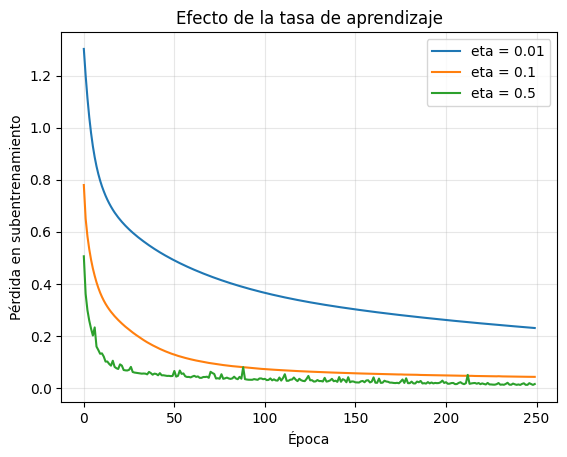

In [ ]:
for eta, valores in curvas.items():
    plt.plot(valores, label=f"eta = {eta}")

plt.title("Efecto de la tasa de aprendizaje")
plt.xlabel("Época")
plt.ylabel("Pérdida en subentrenamiento")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 4.3 Elegir y entrenar el modelo final

En la tabla anterior seleccionamos la combinación con **menor pérdida de validación**. Ya elegida, entrenamos **desde cero** otra red con todos los **120 datos de entrenamiento**, que no incluyen el conjunto de prueba.

In [ ]:
mejor = resultados.iloc[0]
CAPAS_ELEGIDAS = mejor["capas"]
ETA_ELEGIDA = float(mejor["eta"])

modelo = MLP(CAPAS_ELEGIDAS, eta=ETA_ELEGIDA, semilla=SEMILLA)
modelo.fit(X_train_esc, y_train, epocas=EPOCAS)

print("Arquitectura elegida:", CAPAS_ELEGIDAS)
print("Tasa de aprendizaje:", ETA_ELEGIDA)
print("Pérdida final:", round(modelo.historial["perdida"][-1], 4))
print("Exactitud en entrenamiento:", f'{modelo.historial["exactitud"][-1]:.2%}')
print("Cantidad de pesos y sesgos:", sum(W.size + b.size for W, b in zip(modelo.W, modelo.b)))

Arquitectura elegida: [4, 5, 3]
Tasa de aprendizaje: 0.1
Pérdida final: 0.0508
Exactitud en entrenamiento: 98.33%
Cantidad de pesos y sesgos: 43


### 4.4 Ver cómo aprendió nuestra red

Una red que aprende normalmente disminuye su **pérdida** y aumenta su **exactitud**. Ambas medidas se calcularon después de cada época.

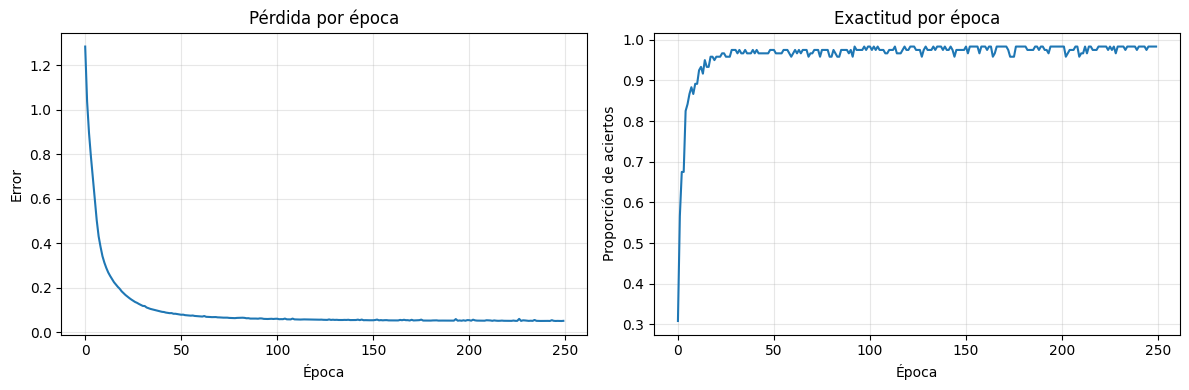

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(modelo.historial["perdida"])
ejes[0].set_title("Pérdida por época")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Error")

ejes[1].plot(modelo.historial["exactitud"])
ejes[1].set_title("Exactitud por época")
ejes[1].set_xlabel("Época")
ejes[1].set_ylabel("Proporción de aciertos")

for eje in ejes:
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Evaluación final con las 30 flores de prueba

Ahora sí usamos las flores que nunca se emplearon para entrenar ni seleccionar la red.

\[
Accuracy = \frac{\text{aciertos}}{\text{total de flores de prueba}}
\]

Comparamos los resultados de entrenamiento y prueba para tener una idea del desempeño en flores nuevas.

In [ ]:
predicciones = modelo.predict(X_test_esc)
acc_train = exactitud(y_train, modelo.predict(X_train_esc))
acc_test = exactitud(y_test, predicciones)

print(f"Exactitud en entrenamiento: {acc_train:.2%}")
print(f"Exactitud en prueba:        {acc_test:.2%}")

Exactitud en entrenamiento: 98.33%
Exactitud en prueba:        100.00%


### 5.1 Construir una matriz de confusión usando NumPy

La fila representa la especie **real** y la columna la especie **predicha**. La diagonal son los aciertos. Si hay un número fuera de la diagonal, significa que la red confundió dos especies.

            setosa  versicolor  virginica
setosa          10           0          0
versicolor       0          10          0
virginica        0           0         10


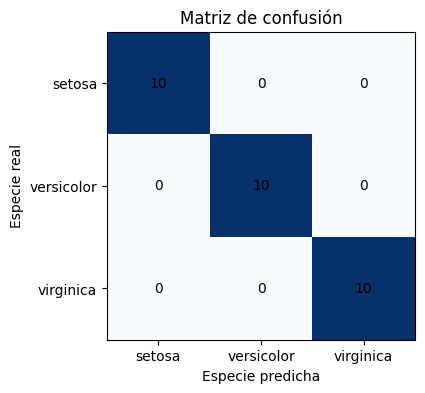

In [ ]:
def matriz_confusion(reales, predichas, K):
    matriz = np.zeros((K, K), dtype=int)
    for real, pred in zip(reales, predichas):
        matriz[real, pred] += 1
    return matriz

matriz = matriz_confusion(y_test, predicciones, K)
print(pd.DataFrame(matriz, index=clases, columns=clases))

fig, eje = plt.subplots(figsize=(5, 4))
eje.imshow(matriz, cmap="Blues")
for fila in range(K):
    for columna in range(K):
        eje.text(columna, fila, matriz[fila, columna], ha="center", va="center")
eje.set_xticks(range(K), clases)
eje.set_yticks(range(K), clases)
eje.set_xlabel("Especie predicha")
eje.set_ylabel("Especie real")
eje.set_title("Matriz de confusión")
plt.show()

### 5.2 Calcular precisión, recall y F1 por especie

- **Precisión:** de las flores que etiquetamos con cierta especie, qué proporción era correcta.
- **Recall:** de todas las flores de esa especie, cuántas encontramos.
- **F1:** combina precisión y recall.

Vamos a calcular las tres medidas **sin utilizar funciones de métricas de scikit-learn**.

In [ ]:
aciertos = np.diag(matriz).astype(float)
predichas_por_clase = matriz.sum(axis=0)
reales_por_clase = matriz.sum(axis=1)

# El "where" evita dividir entre cero si una clase no recibe predicciones.
precision = np.divide(aciertos, predichas_por_clase,
                      out=np.zeros(K), where=predichas_por_clase > 0)
recall = np.divide(aciertos, reales_por_clase,
                   out=np.zeros(K), where=reales_por_clase > 0)
f1 = np.divide(2 * precision * recall, precision + recall,
               out=np.zeros(K), where=(precision + recall) > 0)

reporte = pd.DataFrame({"Precision": precision, "Recall": recall,
                        "F1": f1, "Muestras": reales_por_clase}, index=clases)
print(reporte.round(3))

            Precision  Recall   F1  Muestras
setosa            1.0     1.0  1.0        10
versicolor        1.0     1.0  1.0        10
virginica         1.0     1.0  1.0        10


## 6. Verificación contra scikit-learn

Solo para comprobar nuestro trabajo, contrastamos el **accuracy** y la **matriz de confusión** con funciones de `scikit-learn`. Además entrenamos un MLP de esa biblioteca como **referencia adicional**.

Los dos modelos no tienen por qué obtener exactamente la misma exactitud: aunque reciban datos similares, sus pesos iniciales y métodos de optimización pueden ser diferentes.

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.neural_network import MLPClassifier

print("¿Coincide el accuracy?:", np.isclose(acc_test, accuracy_score(y_test, predicciones)))
print("¿Coincide la matriz?:", np.array_equal(matriz, confusion_matrix(y_test, predicciones)))

referencia = MLPClassifier(
    hidden_layer_sizes=tuple(CAPAS_ELEGIDAS[1:-1]),
    max_iter=1500,
    random_state=SEMILLA
)
referencia.fit(X_train_esc, y_train)
acc_referencia = accuracy_score(y_test, referencia.predict(X_test_esc))
print(f"Nuestro MLP desde cero:  {acc_test:.2%}")
print(f"MLP de scikit-learn:     {acc_referencia:.2%}")

¿Coincide el accuracy?: True
¿Coincide la matriz?: True


Nuestro MLP desde cero:  100.00%
MLP de scikit-learn:     100.00%


## 7. Predecir una flor nueva

La red espera cuatro medidas en este orden: **largo del sépalo, ancho del sépalo, largo del pétalo, ancho del pétalo** (en centímetros).

Recuerda: primero se escala usando las **medias y desviaciones del entrenamiento**; después se calculan las probabilidades.

In [ ]:
flor_nueva = np.array([[6.0, 2.9, 4.5, 1.5]])
flor_escalada = escalar(flor_nueva, mu, sigma)
probabilidades = modelo.predict_proba(flor_escalada)[0]
clase_predicha = modelo.predict(flor_escalada)[0]

for nombre, probabilidad in zip(clases, probabilidades):
    print(f"{nombre}: {probabilidad:.2%}")
print("Especie predicha:", clases[clase_predicha])

setosa: 0.04%
versicolor: 98.89%
virginica: 1.07%
Especie predicha: versicolor


## 8. Conclusiones

- Construimos una **red neuronal multiclase desde cero con NumPy**: pesos, sesgos, funciones de activación, *forward pass*, pérdida, *backpropagation*, ajuste de pesos y predicción.
- Programamos la **división estratificada**, el escalado y la **matriz de confusión** en vez de depender de bibliotecas que los hagan automáticamente.
- Utilizamos **validación** para comparar arquitecturas y tasas de aprendizaje antes de evaluar con los datos de prueba.
- Verificamos los gradientes numéricamente y comprobamos el resultado de nuestras métricas mediante `scikit-learn`.

### Preguntas de repaso (con respuestas)

**1. ¿Qué hacen los pesos?** Determinan cuánto influye cada entrada en una neurona.

**2. ¿Qué hace el forward pass?** Calcula la predicción desde las entradas hasta la capa de salida.

**3. ¿Para qué sirve backpropagation?** Para calcular cómo cambiar los pesos y sesgos a fin de reducir el error.

**4. ¿Qué es una época?** Una vuelta completa por el conjunto de entrenamiento.

**5. ¿Por qué usamos validación antes de prueba?** Para elegir el modelo sin tomar decisiones basadas en los ejemplos reservados para la evaluación final.

### Bibliografía breve
- Material original del Hands-on 4 y fundamentos de redes neuronales artificiales (ANN).
- Documentación de NumPy: [operaciones con matrices](https://numpy.org/doc/stable/reference/generated/numpy.matmul.html).
- Documentación de scikit-learn: [Iris](https://scikit-learn.org/stable/datasets/toy_dataset.html#iris-dataset).
- Matt Mazur: [A Step by Step Backpropagation Example](https://mattmazur.com/2015/03/17/a-step-by-step-backpropagation-example/).